# Customer Intelligence — Segmentação de Clientes

## Objetivo

Construir um modelo de segmentação de clientes utilizando o conjunto de dados Online Retail, previamente explorado e tratado na etapa anterior, para identificar grupos de consumidores com padrões semelhantes de comportamento de compra.

Nesta etapa, serão construídas as métricas RFM (Recency, Frequency e Monetary), aplicadas técnicas de preparação e padronização dos dados e utilizado o algoritmo K-Means para identificar diferentes segmentos de clientes.

O resultado servirá como base para compreender o perfil dos consumidores e desenvolver estratégias de negócio direcionadas, além de possibilitar futuras aplicações utilizando Inteligência Artificial Generativa.

In [3]:
import pandas as pd
import numpy as np

df_clean = pd.read_csv(
    "../data/processed/customer_transactions_clean.csv",
    encoding="utf-8"
)

print("Dimensões:", df_clean.shape)
df_clean.head()

Dimensões: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
# Garantir conversão correta da data
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Definir data de referência estática baseada no fim do histórico
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

In [4]:
print("Tipo da coluna:", df_clean["InvoiceDate"].dtype)

print("\nPrimeiros valores:")
print(df_clean["InvoiceDate"].head())

print("\nValores ausentes:")
print(df_clean["InvoiceDate"].isna().sum())

Tipo da coluna: datetime64[us]

Primeiros valores:
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]

Valores ausentes:
0


In [5]:
data_referencia = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Última compra registrada:", df_clean["InvoiceDate"].max())
print("Data de referência:", data_referencia)

Última compra registrada: 2011-12-09 12:50:00
Data de referência: 2011-12-10 12:50:00


In [7]:
# Garantir conversão correta da data
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Definir data de referência estática baseada no fim do histórico
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Data de referência:", snapshot_date)

Data de referência: 2011-12-10 12:50:00


In [8]:
# Agregação por cliente
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recência (dias)
    'InvoiceNo': 'nunique',                                   # Frequência (compras únicas)
    'TotalPrice': 'sum'                                       # Valor Monetário (R$)
}).reset_index()

# Renomear colunas
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# Filtrar eventuais clientes com valor monetário <= 0 (devoluções não compensadas)
rfm = rfm[rfm['Monetary'] > 0].copy()

In [9]:
print("Dimensões da tabela RFM:", rfm.shape)

print("\nPrimeiros registros:")
display(rfm.head())

print("\nClientes únicos:", rfm["CustomerID"].nunique())

print("\nValores ausentes:")
print(rfm.isna().sum())

print("\nClientes duplicados:")
print(rfm["CustomerID"].duplicated().sum())

Dimensões da tabela RFM: (4338, 4)

Primeiros registros:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40



Clientes únicos: 4338

Valores ausentes:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Clientes duplicados:
0


In [10]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [16]:
rfm[["Recency", "Frequency", "Monetary"]].skew()

Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

In [15]:
from sklearn.preprocessing import StandardScaler

# 1. Transformação Logarítmica para suavizar outliers e assimetria
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# 2. Padronização (Média = 0, Desvio Padrão = 1)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Converter de volta para DataFrame para facilitar leitura se necessário
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(rfm_scaled_df)

    resultados.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(rfm_scaled_df, clusters)
    })

resultados_df = pd.DataFrame(resultados)

display(resultados_df.round(4))

,K,Inertia,Silhouette
0,2,6483.5894,0.4328
1,3,4869.4886,0.3365
2,4,3939.0494,0.3375
3,5,3296.7087,0.3162
4,6,2855.7641,0.3124
5,7,2548.8202,0.3092
6,8,2336.3411,0.3033
7,9,2156.0057,0.2811
8,10,2005.7462,0.2767


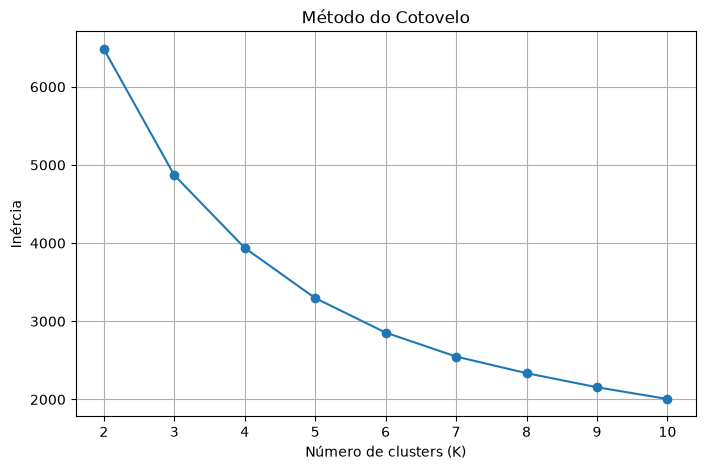

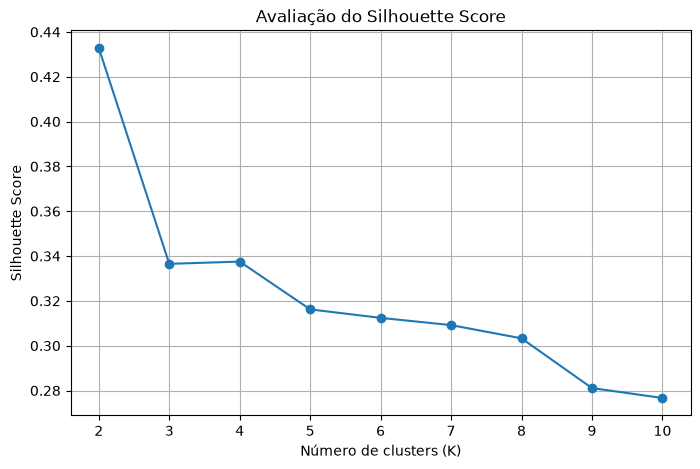

In [21]:
import matplotlib.pyplot as plt

# Gráfico do método do cotovelo
plt.figure(figsize=(8, 5))
plt.plot(
    resultados_df["K"],
    resultados_df["Inertia"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo")
plt.xticks(resultados_df["K"])
plt.grid(True)
plt.show()


# Gráfico do Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(
    resultados_df["K"],
    resultados_df["Silhouette"],
    marker="o"
)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Avaliação do Silhouette Score")
plt.xticks(resultados_df["K"])
plt.grid(True)
plt.show()

In [23]:
# Treinar o algoritmo
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Exibir os primeiros clientes agrupados
print(rfm.head())

   CustomerID  Recency  Frequency  Monetary  Cluster
0     12346.0      326          1  77183.60        3
1     12347.0        2          7   4310.00        0
2     12348.0       75          4   1797.24        3
3     12349.0       19          1   1757.55        2
4     12350.0      310          1    334.40        1


In [24]:
analise_clusters = rfm.groupby("Cluster").agg({
    "CustomerID": "count",
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

analise_clusters = analise_clusters.rename(columns={
    "CustomerID": "Quantidade_Clientes"
})

display(analise_clusters)

,Quantidade_Clientes,Recency,Frequency,Monetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


In [27]:
# Dicionário de mapeamento baseado na interpretação das médias
cluster_names = {
    0: 'Clientes VIP',
    1: 'Clientes Inativos',
    2: 'Clientes Regulares',
    3: 'Clientes Promissores'
}

# Criar a coluna formatada
rfm['Segmento'] = rfm['Cluster'].map(cluster_names)

# Visualizando os primeiros registros
display(rfm.head())

,CustomerID,Recency,Frequency,Monetary,Cluster,Segmento
0,12346.0,326,1,77183.60,3,Clientes Promissores
1,12347.0,2,7,4310.00,0,Clientes VIP
2,12348.0,75,4,1797.24,3,Clientes Promissores
3,12349.0,19,1,1757.55,2,Clientes Regulares
4,12350.0,310,1,334.40,1,Clientes Inativos


In [30]:
mapa_segmentos = (
    rfm.drop_duplicates("Cluster")
    .set_index("Cluster")["Segmento"]
    .to_dict()
)

print(mapa_segmentos)

{3: 'Clientes Promissores', 0: 'Clientes VIP', 2: 'Clientes Regulares', 1: 'Clientes Inativos'}


In [31]:
resumo_segmentos = rfm.groupby("Segmento").agg(
    Quantidade_Clientes=("CustomerID", "count"),
    Recency_Media=("Recency", "mean"),
    Frequency_Media=("Frequency", "mean"),
    Monetary_Medio=("Monetary", "mean")
)

resumo_segmentos["Participacao_%"] = (
    resumo_segmentos["Quantidade_Clientes"] / len(rfm) * 100
)

display(resumo_segmentos.round(2))

,Quantidade_Clientes,Recency_Media,Frequency_Media,Monetary_Medio,Participacao_%
Segmento,,,,,
Clientes Inativos,1622,181.51,1.32,341.00,37.39
Clientes Promissores,1166,71.64,4.08,1801.78,26.88
Clientes Regulares,837,17.70,2.19,557.32,19.29
Clientes VIP,713,12.17,13.75,8088.02,16.44


In [32]:
import joblib
from pathlib import Path

# Criar diretórios
Path("../models").mkdir(parents=True, exist_ok=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

# 1. Salvar os modelos e o mapeamento
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(kmeans, "../models/kmeans_model.pkl")
joblib.dump(mapa_segmentos, "../models/mapa_segmentos.pkl")

# 2. Salvar a base final segmentada
rfm.to_csv(
    "../data/processed/rfm_segmented_customers.csv",
    index=False,
    encoding="utf-8"
)

print("Modelos e dados salvos com sucesso!")

Modelos e dados salvos com sucesso!


## Persistência dos Modelos e Reutilização

Após o treinamento do K-Means, os modelos e os dados segmentados foram salvos em disco para permitir sua reutilização em outras etapas do projeto, sem a necessidade de realizar um novo treinamento.

Foram persistidos os seguintes artefatos:

- **scaler.pkl:** objeto `StandardScaler` treinado, responsável pela padronização das variáveis RFM.
- **kmeans_model.pkl:** modelo K-Means treinado, responsável pela atribuição dos clientes aos clusters.
- **mapa_segmentos.pkl:** dicionário que relaciona os identificadores numéricos dos clusters aos respectivos nomes dos segmentos de negócio.
- **rfm_segmented_customers.csv:** base final contendo os clientes, suas variáveis RFM, os clusters atribuídos e os nomes dos segmentos.

### Reutilização dos modelos

Para classificar novos clientes futuramente, será necessário seguir exatamente a mesma sequência de pré-processamento utilizada durante o treinamento:

1. Construir as variáveis RFM dos novos clientes.
2. Aplicar a transformação logarítmica `np.log1p()` nas variáveis Recency, Frequency e Monetary.
3. Aplicar o `StandardScaler` previamente treinado, utilizando o método `transform()`, sem realizar um novo ajuste (`fit`).
4. Utilizar o método `predict()` do modelo K-Means salvo para identificar o cluster de cada cliente.
5. Consultar o dicionário de segmentos para associar o identificador do cluster ao respectivo perfil de negócio.

**Importante:** os novos dados devem utilizar as mesmas variáveis, na mesma ordem, e o mesmo processo de transformação empregado durante o treinamento. O scaler e o K-Means devem ser reutilizados em conjunto para preservar a consistência da segmentação.

Essa abordagem permite integrar futuramente o modelo a uma API ou dashboard, possibilitando a classificação de novos clientes sem precisar treinar novamente o algoritmo.